# Notebook 01 - SCMS shipment history: EDA, cleaning and features

**PharmaShield GCC** - Group 3, AI in Operations (Dr. Sandip Kumar Roy), SP Jain School of Global Management, Dubai.
Academic prototype for a hypothetical UAE healthcare group purchasing organisation (GPO). Not a real company.

| Item | Value |
|---|---|
| Build steps covered | Build step 1 - Clean SCMS training data; Build step 2 - Engineer site and corridor features |
| Key questions served | Q2 (data sources), Q3 (disruption prediction, training layer) |
| Input | data/raw/scms_shipment_pricing.csv (USAID SCMS Delivery History, Kaggle copy, assumption A19) |
| Outputs | data/processed/scms_clean.csv, data/processed/site_features.csv, figures/fig_01 to fig_04 |
| Random seed | 42 |

## 1. Objective

**Section intro.** The GPO wants to know which carboplatin makers are most likely to deliver late. It has no shipment history of its own we can use, so we learn the physics of pharmaceutical freight from the public USAID SCMS file: about 10,000 real shipments from 2006 to 2015.

This notebook turns the raw file into a clean, model-ready table. It does four things:
1. Parses dates and builds the target `late` (delivered after the scheduled date).
2. Turns text placeholders in the freight, weight and insurance columns into numbers or explicit missing values.
3. Derives the **origin country** from the manufacturing site. Important: the SCMS column `Country` is the **destination** country, not the origin (override 2).
4. Engineers transferable features (origin country, shipment mode, freight-to-value ratio, weight) and descriptive site statistics.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[0]))  # pipeline/ on the path, so "src" imports work

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.common import RAW, PROCESSED, REFERENCE, RANDOM_STATE, PALETTE, style, save_fig, shape

style()
np.random.seed(RANDOM_STATE)
print("pandas", pd.__version__, "| seaborn", sns.__version__, "| random_state", RANDOM_STATE)

pandas 2.2.3 | seaborn 0.13.2 | random_state 42


**Section summary.** The environment is fixed: pinned library versions (app/requirements-lock.txt) and one seed, so every number in this notebook is reproducible.

## 2. Exploratory data analysis

**Section intro.** Before cleaning anything we look at what the file really contains: its size, which columns hold text where numbers are expected, how often shipments are late, and how that changes over time and by shipment mode.

In [2]:
scms_raw = pd.read_csv(RAW / "scms_shipment_pricing.csv", encoding="utf-8-sig")
shape("Raw SCMS file", scms_raw)
print("Columns:", list(scms_raw.columns))

Raw SCMS file: 10,324 rows x 33 columns
Columns: ['ID', 'Project Code', 'PQ #', 'PO / SO #', 'ASN/DN #', 'Country', 'Managed By', 'Fulfill Via', 'Vendor INCO Term', 'Shipment Mode', 'PQ First Sent to Client Date', 'PO Sent to Vendor Date', 'Scheduled Delivery Date', 'Delivered to Client Date', 'Delivery Recorded Date', 'Product Group', 'Sub Classification', 'Vendor', 'Item Description', 'Molecule/Test Type', 'Brand', 'Dosage', 'Dosage Form', 'Unit of Measure (Per Pack)', 'Line Item Quantity', 'Line Item Value', 'Pack Price', 'Unit Price', 'Manufacturing Site', 'First Line Designation', 'Weight (Kilograms)', 'Freight Cost (USD)', 'Line Item Insurance (USD)']


**Business interpretation.** We have 10,324 real pharmaceutical shipment lines with 33 fields. The file was found exactly as the plan describes, with one name difference: the weight column is called "Weight (Kilograms)". This is the training layer only: these are ARV and HIV test shipments, not carboplatin, so the model learns how freight behaves, not who the 2026 suppliers are.

In [3]:
# Which "numeric" columns contain text, and how much?
check_cols = ["Freight Cost (USD)", "Weight (Kilograms)", "Line Item Insurance (USD)",
              "PO Sent to Vendor Date", "Scheduled Delivery Date", "Delivered to Client Date"]
rows = []
for col in check_cols:
    s = scms_raw[col]
    as_num = pd.to_numeric(s, errors="coerce")
    as_date = pd.to_datetime(s, format="mixed", errors="coerce") if "Date" in col else pd.Series(np.nan, index=s.index)
    text_mask = as_num.isna() & as_date.isna() & s.notna()
    top_text = s[text_mask].astype(str).str.replace(r"See .*", "See <other line>", regex=True).value_counts().head(3)
    rows.append({"column": col, "missing": int(s.isna().sum()), "text_values": int(text_mask.sum()),
                 "top_text_values": "; ".join(f"{k} ({v:,})" for k, v in top_text.items())})
quality = pd.DataFrame(rows)
quality

,column,missing,text_values,top_text_values
0,Freight Cost (USD),0,4126,"See <other line> (2,445); Freight Included in Commodity Cost (1,442); Invoiced Separately (239)"
1,Weight (Kilograms),0,3952,"See <other line> (2,445); Weight Captured Separately (1,507)"
2,Line Item Insurance (USD),287,0,
3,PO Sent to Vendor Date,0,5732,"N/A - From RDC (5,404); Date Not Captured (328)"
4,Scheduled Delivery Date,0,0,
5,Delivered to Client Date,0,0,


**Business interpretation.** Freight cost and weight are text in about 4 of every 10 lines (4,126 and 3,952 lines). Most of that text is not missing data: 2,445 lines say the cost was billed on another line, and 1,442 say freight was included in the product price. Treating those as blanks would throw away a quarter of the cost evidence, so we resolve them. The PO-sent date is text in 5,732 lines (55.5%), too thin to rely on.

In [4]:
sched = pd.to_datetime(scms_raw["Scheduled Delivery Date"], format="mixed", errors="coerce")
deliv = pd.to_datetime(scms_raw["Delivered to Client Date"], format="mixed", errors="coerce")
eda = pd.DataFrame({"year": sched.dt.year, "late": (deliv > sched).astype(int),
                    "mode": scms_raw["Shipment Mode"].fillna("Not recorded")})
by_year = eda.groupby("year").agg(shipments=("late", "size"), late_rate=("late", "mean"))
by_mode = eda.groupby("mode").agg(shipments=("late", "size"), late_rate=("late", "mean")).sort_values("shipments", ascending=False)
print(f"Overall late rate: {eda['late'].mean():.1%} of {len(eda):,} lines")
print(by_year.round(3).to_string())
print()
print(by_mode.round(3).to_string())

Overall late rate: 11.5% of 10,324 lines
      shipments  late_rate
year                      
2006         65      0.000
2007        672      0.021
2008       1029      0.013
2009       1253      0.036
2010       1204      0.159
2011       1011      0.235
2012       1273      0.079
2013       1272      0.179
2014       1528      0.154
2015       1017      0.118

              shipments  late_rate
mode                              
Air                6113      0.096
Truck              2830      0.161
Air Charter         650      0.115
Ocean               371      0.175
Not recorded        360      0.011


**Business interpretation.** About 1 shipment line in 9 (11.5%) arrived after the scheduled date. Lateness is not stable over time: it ranges from 1.3% in 2008 to 23.5% in 2011. Truck and ocean lines are late more often (16.1% and 17.5%) than air lines (9.6%). For the GPO this means delivery risk is real, varies by lane, and must be tested on a later period than the one used for learning.

Saved figures\fig_01_scms_late_rate_year_mode.png


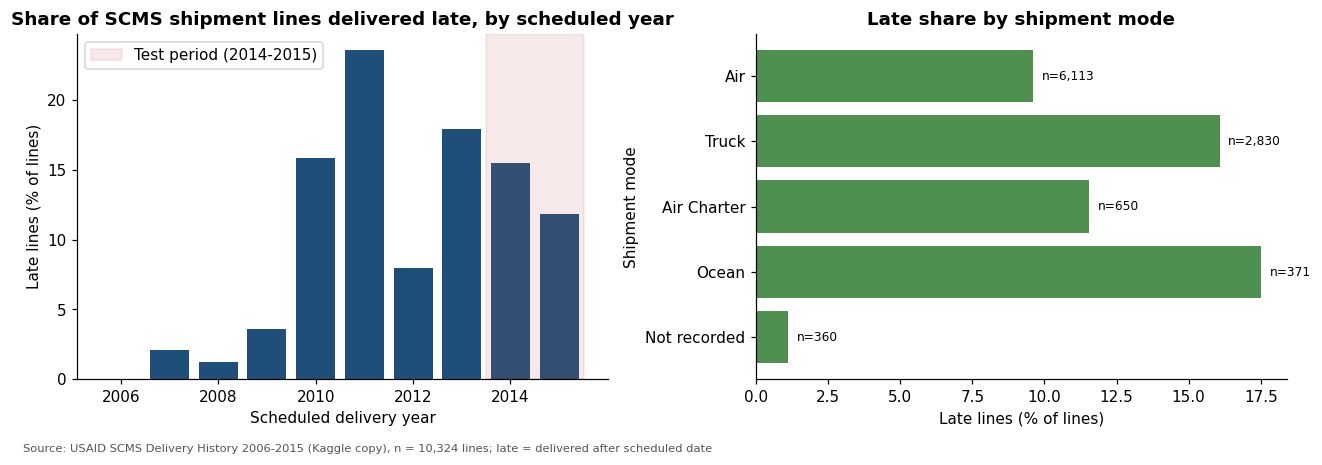

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(by_year.index.astype(int), by_year["late_rate"] * 100, color=PALETTE[0])
axes[0].axvspan(2013.5, 2015.5, color=PALETTE[1], alpha=0.12, label="Test period (2014-2015)")
axes[0].set_title("Share of SCMS shipment lines delivered late, by scheduled year")
axes[0].set_xlabel("Scheduled delivery year")
axes[0].set_ylabel("Late lines (% of lines)")
axes[0].legend(loc="upper left")
order = by_mode.index.tolist()
axes[1].barh(order, by_mode["late_rate"] * 100, color=PALETTE[2])
for i, (n, r) in enumerate(zip(by_mode["shipments"], by_mode["late_rate"])):
    axes[1].text(r * 100 + 0.3, i, f"n={n:,}", va="center", fontsize=8)
axes[1].set_title("Late share by shipment mode")
axes[1].set_xlabel("Late lines (% of lines)")
axes[1].set_ylabel("Shipment mode")
axes[1].invert_yaxis()
save_fig(fig, "fig_01_scms_late_rate_year_mode", "USAID SCMS Delivery History 2006-2015 (Kaggle copy), n = 10,324 lines; late = delivered after scheduled date")
plt.show()

**Business interpretation.** The left chart shows why we split by time: the test years 2014 and 2015 (15.4% and 11.8% late) look different from the early years. A model judged on random rows would look better than it really is. The right chart shows that mode matters, which is one of the inputs we can set for each 2026 maker.

**Section summary.** The file is usable but messy: freight, weight and insurance mix numbers with text, dates come in two formats, and the late rate moves a lot between years. Preprocessing must handle each of these explicitly, and the model must be judged on a later period than it is trained on.

## 3. Preprocessing (Build step 1 - Clean SCMS training data)

**Section intro.** Each step below prints the table shape before and after, so nothing is dropped silently. Rules:
- Dates are parsed with `errors="coerce"`; rows without a valid scheduled or delivered date cannot carry a target and are dropped.
- Freight and weight text is resolved, not deleted: "See <line>" references are allocated from the referenced line, "Freight Included in Commodity Cost" becomes zero extra freight, and "Invoiced Separately" or "Weight Captured Separately" become explicit missing values.
- The PO-sent lead-time column is dropped (override 2): over half of it is text.

### 3.1 Parse dates and build the target

In [6]:
df = scms_raw.copy()
shape("Before date parsing", df)
for col in ["Scheduled Delivery Date", "Delivered to Client Date", "Delivery Recorded Date", "PQ First Sent to Client Date"]:
    df[col] = pd.to_datetime(df[col], format="mixed", errors="coerce")
n_before = len(df)
df = df.dropna(subset=["Scheduled Delivery Date", "Delivered to Client Date"]).copy()
df["delay_days"] = (df["Delivered to Client Date"] - df["Scheduled Delivery Date"]).dt.days
df["late"] = (df["delay_days"] > 0).astype(int)
df["sched_year"] = df["Scheduled Delivery Date"].dt.year
shape("After date parsing", df)
print(f"Rows dropped for missing dates: {n_before - len(df)}")
print(f"Target 'late': {df['late'].sum():,} late of {len(df):,} lines = {df['late'].mean():.2%}")
print("Delay days when late: median", df.loc[df.late == 1, "delay_days"].median(), "| 90th percentile", df.loc[df.late == 1, "delay_days"].quantile(0.9))

Before date parsing: 10,324 rows x 33 columns


After date parsing: 10,324 rows x 36 columns
Rows dropped for missing dates: 0
Target 'late': 1,186 late of 10,324 lines = 11.49%


Delay days when late: median 12.0 | 90th percentile 51.0


**Business interpretation.** Every line has a valid scheduled and delivered date, so no rows are lost and the target covers the full file: 1,186 late lines out of 10,324 (11.49%). When a line is late, the median delay is 12 days and 1 in 10 late lines is 51 or more days late. For an oncology ward, a 12-day slip on a chemotherapy drug is a missed treatment cycle.

### 3.2 Resolve freight cost text

In [7]:
import re

shape("Before freight resolution", df)
raw_freight = df["Freight Cost (USD)"].astype(str).str.strip()
freight_num = pd.to_numeric(raw_freight, errors="coerce")
ref_id = raw_freight.str.extract(r"ID#:(\d+)")[0].astype(float)
df["freight_status"] = np.select(
    [freight_num.notna(), raw_freight.eq("Freight Included in Commodity Cost"), ref_id.notna(), raw_freight.eq("Invoiced Separately")],
    ["numeric", "included_in_commodity", "see_other_line", "invoiced_separately"], default="other_text")
print(df["freight_status"].value_counts().to_string())

# "See ASN-93 (ID#:1281)" means the freight for this line was billed on line ID 1281.
# Allocate that bill across the referenced line and every line pointing to it, in proportion to line value.
df["freight_group"] = np.where(ref_id.notna(), ref_id, df["ID"]).astype(int)
id_to_freight = pd.Series(freight_num.values, index=df["ID"].values)
group_bill = df["freight_group"].map(id_to_freight)
group_value = df.groupby("freight_group")["Line Item Value"].transform("sum")
value_share = np.where(group_value > 0, df["Line Item Value"] / group_value, np.nan)
df["freight_usd"] = np.where(df["freight_status"].eq("included_in_commodity"), 0.0,
                    np.where(df["freight_status"].isin(["numeric", "see_other_line"]), group_bill * value_share, np.nan))
shape("After freight resolution", df)
print(f"Lines with a usable freight value: {df['freight_usd'].notna().sum():,} ({df['freight_usd'].notna().mean():.1%})")
print(f"'See other line' references resolved to a number: {(df['freight_status'].eq('see_other_line') & df['freight_usd'].notna()).sum():,} of {df['freight_status'].eq('see_other_line').sum():,}")

Before freight resolution: 10,324 rows x 36 columns
freight_status
numeric                  6198
see_other_line           2445
included_in_commodity    1442
invoiced_separately       239
After freight resolution: 10,324 rows x 39 columns
Lines with a usable freight value: 9,967 (96.5%)
'See other line' references resolved to a number: 2,339 of 2,445


**Business interpretation.** Freight is now usable for 9,967 lines (96.5%) instead of 6,198 (60.0%). The 2,445 "see other line" references were allocated from the referenced bill in proportion to line value; 2,339 of them resolved to a number. Only 239 lines invoiced separately and the unresolved references stay missing, and they are flagged rather than guessed.

### 3.3 Resolve weight and insurance

In [8]:
shape("Before weight and insurance resolution", df)
raw_weight = df["Weight (Kilograms)"].astype(str).str.strip()
weight_num = pd.to_numeric(raw_weight, errors="coerce")
w_ref = raw_weight.str.extract(r"ID#:(\d+)")[0].astype(float)
df["weight_group"] = np.where(w_ref.notna(), w_ref, df["ID"]).astype(int)
id_to_weight = pd.Series(weight_num.values, index=df["ID"].values)
w_bill = df["weight_group"].map(id_to_weight)
w_value = df.groupby("weight_group")["Line Item Value"].transform("sum")
w_share = np.where(w_value > 0, df["Line Item Value"] / w_value, np.nan)
df["weight_kg"] = np.where(weight_num.notna() | w_ref.notna(), w_bill * w_share, np.nan)
df.loc[df["weight_kg"] <= 0, "weight_kg"] = np.nan
df["insurance_usd"] = pd.to_numeric(df["Line Item Insurance (USD)"], errors="coerce")
shape("After weight and insurance resolution", df)
print(f"Usable weight: {df['weight_kg'].notna().sum():,} lines ({df['weight_kg'].notna().mean():.1%}); text 'Weight Captured Separately': {raw_weight.eq('Weight Captured Separately').sum():,}")
print(f"Usable insurance: {df['insurance_usd'].notna().sum():,} lines; missing: {df['insurance_usd'].isna().sum():,}")

Before weight and insurance resolution: 10,324 rows x 39 columns
After weight and insurance resolution: 10,324 rows x 42 columns
Usable weight: 8,676 lines (84.0%); text 'Weight Captured Separately': 1,507
Usable insurance: 10,037 lines; missing: 287


**Business interpretation.** Weight is usable for 8,676 lines (84.0%). The 1,507 lines with "Weight Captured Separately" stay missing rather than being filled with an average. Insurance is missing for 287 lines (2.8%). Missing values stay missing on purpose: the gradient-boosting model in notebook 03 handles them natively, and imputing them would hide the gap.

### 3.4 Origin country from the manufacturing site (override 2)

In [9]:
shape("Before origin mapping", df)
site_map = pd.read_csv(REFERENCE / "site_country_map.csv")
print(f"Reviewed site map: {len(site_map)} sites, {site_map['confidence'].value_counts().to_dict()}")
df = df.merge(site_map[["manufacturing_site", "origin_country", "confidence"]], how="left",
              left_on="Manufacturing Site", right_on="manufacturing_site").drop(columns="manufacturing_site")
unmapped = df["origin_country"].isna().sum()
assert unmapped == 0, f"{unmapped} lines have a site missing from the map"
shape("After origin mapping", df)
origin_counts = df["origin_country"].value_counts()
print("Lines by origin country:")
print(origin_counts.to_string())
print(f"\nDestination countries (SCMS 'Country' column, not used as a model feature): {df['Country'].nunique()}")

Before origin mapping: 10,324 rows x 42 columns
Reviewed site map: 88 sites, {'explicit': 72, 'inferred': 16}
After origin mapping: 10,324 rows x 44 columns
Lines by origin country:
origin_country
India             7156
Japan              828
Germany            448
Ireland            405
United Kingdom     267
France             213
United States      207
South Africa       184
Netherlands        121
South Korea        114
Italy               79
China               72
Canada              64
Switzerland         50
Thailand            43
Spain               34
Unknown             17
Greece              13
Poland               3
Australia            2
Cyprus               2
Israel               1
Norway               1

Destination countries (SCMS 'Country' column, not used as a model feature): 43


**Business interpretation.** Every line now has an origin country from the 88-site map (72 sites named their country explicitly, 16 were inferred from the firm and are marked as inferred). India dominates with 7,156 lines (69%), which matches the generic ARV supply base. The SCMS "Country" column holds 43 destination countries in Africa, Asia and the Caribbean; the UAE is not one of them, which is why destination is never a model feature.

### 3.5 Drop the PO-sent lead-time column and fix the shipment mode

In [10]:
shape("Before column clean-up", df)
po_text = scms_raw["PO Sent to Vendor Date"].isin(["N/A - From RDC", "Date Not Captured"]).mean()
print(f"PO Sent to Vendor Date unusable (text): {po_text:.1%} of raw lines, so the lead-time feature is dropped (override 2)")
df["shipment_mode"] = df["Shipment Mode"].fillna("Not recorded")
drop_cols = ["PO Sent to Vendor Date", "Freight Cost (USD)", "Weight (Kilograms)", "Line Item Insurance (USD)", "Shipment Mode"]
df = df.drop(columns=drop_cols)
shape("After column clean-up", df)
print(df["shipment_mode"].value_counts().to_string())

Before column clean-up: 10,324 rows x 44 columns
PO Sent to Vendor Date unusable (text): 55.5% of raw lines, so the lead-time feature is dropped (override 2)
After column clean-up: 10,324 rows x 40 columns
shipment_mode
Air             6113
Truck           2830
Air Charter      650
Ocean            371
Not recorded     360


**Business interpretation.** The PO-sent date is unusable in 55.5% of lines, so a lead-time feature built on it would describe less than half the data, and mostly the direct-drop half. We drop it, as override 2 requires. The 360 lines with no shipment mode keep an explicit "Not recorded" label instead of being guessed.

**Section summary.** All 10,324 lines keep a valid target. Text placeholders are now either resolved numbers or explicit missing values with a status flag, so the model can tell "no freight charged" from "freight not recorded". Every line has an origin country from a reviewed, 88-site map.

## 4. Feature engineering (Build step 2 - Engineer site and corridor features)

**Section intro.** The delivery model (C2) uses only features that transfer to 2026 carboplatin makers (assumption A5, override 2): origin country, shipment mode, freight-to-value ratio and weight, plus a site prior built in notebook 03. Insurance-to-value ratio, line value and landed unit cost are also built here because the landed-cost (C1) and anomaly (C3) engines need them. Destination country is excluded because the UAE never appears in SCMS. We also build a descriptive site table (on-time rate, mean and 90th-percentile delay, unit-price variability, air share). The model itself uses site priors computed from the training years only, in notebook 03, to avoid leakage.

In [11]:
shape("Before feature engineering", df)
value = df["Line Item Value"].where(df["Line Item Value"] > 0)
df["freight_to_value"] = (df["freight_usd"] / value).clip(upper=5)
df["insurance_to_value"] = (df["insurance_usd"] / value).clip(upper=1)
df["log_weight_kg"] = np.log1p(df["weight_kg"])
df["log_line_value"] = np.log1p(df["Line Item Value"])
df["is_air"] = df["shipment_mode"].isin(["Air", "Air Charter"]).astype(int)
df["landed_unit_cost"] = (df["Line Item Value"] + df["freight_usd"].fillna(0) + df["insurance_usd"].fillna(0)) / df["Line Item Quantity"]
shape("After feature engineering", df)
feature_summary = df[["freight_to_value", "insurance_to_value", "weight_kg", "Line Item Value", "landed_unit_cost"]].describe(percentiles=[0.5, 0.9]).T
feature_summary[["count", "mean", "50%", "90%", "max"]].round(4)

Before feature engineering: 10,324 rows x 40 columns
After feature engineering: 10,324 rows x 46 columns


,count,mean,50%,90%,max
freight_to_value,9966.0,0.2274,0.0576,0.4349,5.000000e+00
insurance_to_value,10020.0,0.0015,0.0016,0.0022,3.600000e-03
weight_kg,8676.0,2513.7925,649.5974,6075.5475,8.573540e+05
Line Item Value,10324.0,157650.5673,30471.4650,437487.7850,5.951990e+06
landed_unit_cost,10324.0,35.5076,10.2805,75.2535,1.460420e+04


**Business interpretation.** The typical line pays about 5.8% of its value in freight (median 0.0576), but the top 10% pay 43% or more, which is the tail that matters for landed cost and for price anomalies. Insurance is small and stable at about 0.16% of value. Weight and value are very skewed (median 650 kg, maximum 857,354 kg), so the model uses their logarithms.

In [12]:
med_ratio = df.groupby("origin_country").agg(lines=("ID", "size"), air_share=("is_air", "mean"),
                                             median_freight_to_value=("freight_to_value", "median"),
                                             median_insurance_to_value=("insurance_to_value", "median"),
                                             late_rate=("late", "mean")).sort_values("lines", ascending=False)
med_ratio.round(4)

,lines,air_share,median_freight_to_value,median_insurance_to_value,late_rate
origin_country,,,,,
India,7156,0.5886,0.0512,0.0014,0.1448
Japan,828,0.9589,0.0842,0.0014,0.1196
Germany,448,0.7679,0.0416,0.0016,0.0580
Ireland,405,0.9457,0.1486,0.0016,0.0025
United Kingdom,267,0.6479,0.0521,0.0016,0.0150
France,213,0.6150,0.0000,0.0019,0.0282
United States,207,0.8406,0.0868,0.0016,0.0048
South Africa,184,0.5598,0.0093,0.0020,0.0109
Netherlands,121,0.7851,0.0186,0.0016,0.0165


**Business interpretation.** Origin countries differ sharply. India-made lines are late 14.5% of the time with a median freight ratio of 5.1%; German-made lines are late 5.8% of the time; US-made lines are late 0.5% of the time with a higher freight ratio of 8.7%. This table also gives notebook 02 a data-based freight and insurance markup per origin country for the carboplatin landed-cost estimate (C1).

In [13]:
site = df.groupby("Manufacturing Site").agg(
    origin_country=("origin_country", "first"), lines=("ID", "size"), on_time_rate=("late", lambda s: 1 - s.mean()),
    mean_delay_days=("delay_days", lambda s: s.clip(lower=0).mean()),
    p90_delay_days=("delay_days", lambda s: s.clip(lower=0).quantile(0.9)),
    unit_price_cv=("Unit Price", lambda s: s.std() / s.mean() if s.mean() > 0 else np.nan),
    air_share=("is_air", "mean"), median_freight_to_value=("freight_to_value", "median"),
).sort_values("lines", ascending=False)
shape("Site feature table", site)
site.head(12).round(3)

Site feature table: 88 rows x 8 columns


,origin_country,lines,on_time_rate,mean_delay_days,p90_delay_days,unit_price_cv,air_share,median_freight_to_value
Manufacturing Site,,,,,,,,
"Aurobindo Unit III, India",India,3172,0.866,3.119,5.9,1.152,0.619,0.059
Mylan (formerly Matrix) Nashik,India,1415,0.851,3.503,8.0,0.670,0.607,0.042
Hetero Unit III Hyderabad IN,India,869,0.852,3.255,8.0,0.829,0.560,0.048
"Cipla, Goa, India",India,665,0.844,3.374,10.0,0.968,0.472,0.044
"Strides, Bangalore, India.",India,540,0.824,3.574,9.1,0.611,0.576,0.063
"Alere Medical Co., Ltd.",Japan,481,0.842,2.006,4.0,1.070,0.983,0.090
"Trinity Biotech, Plc",Ireland,405,0.998,0.106,0.0,0.794,0.946,0.149
ABBVIE Ludwigshafen Germany,Germany,366,0.932,1.257,0.0,0.677,0.801,0.046
Inverness Japan,Japan,345,0.933,0.797,0.0,0.519,0.928,0.071


**Business interpretation.** Sites with the same origin country still differ: among the big Indian sites, on-time rates range from 82.4% (Strides, Bangalore) to 86.6% (Aurobindo Unit III), and the 90th-percentile delay ranges from 5.9 to 10 days. Aurobindo Unit III matters directly for the GPO: Aurobindo is the parent of Eugia, one of the 11 carboplatin makers, so its record feeds the site prior.

Saved figures\fig_02_scms_origin_freight.png


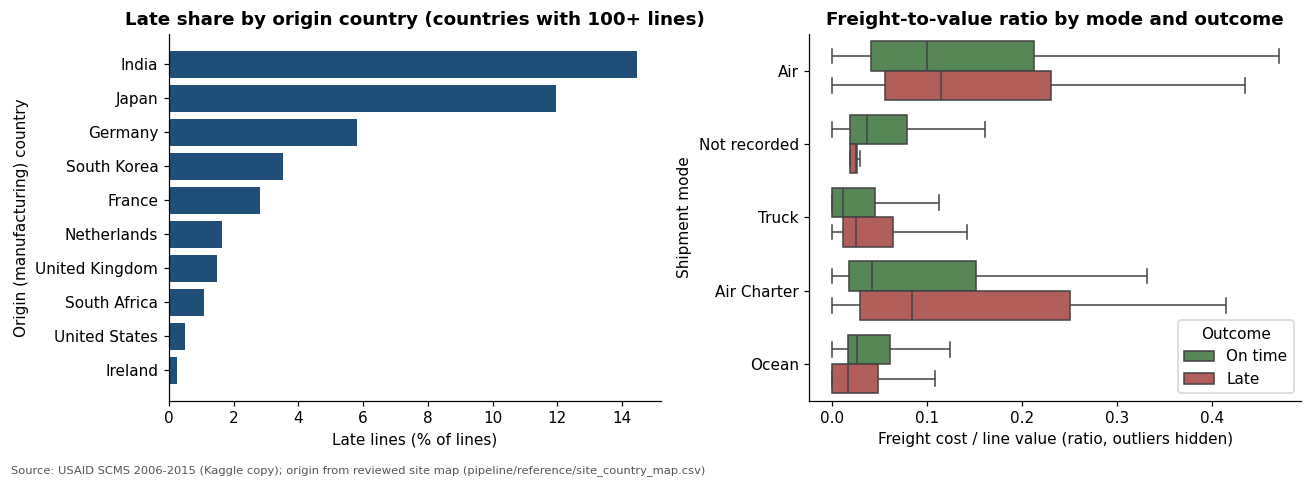

In [14]:
top_origins = origin_counts[origin_counts >= 100].index.tolist()
plot_df = df[df["origin_country"].isin(top_origins)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
rate = plot_df.groupby("origin_country")["late"].mean().sort_values() * 100
axes[0].barh(rate.index, rate.values, color=PALETTE[0])
axes[0].set_title("Late share by origin country (countries with 100+ lines)")
axes[0].set_xlabel("Late lines (% of lines)")
axes[0].set_ylabel("Origin (manufacturing) country")
sns.boxplot(data=plot_df[plot_df["freight_to_value"].notna()], x="freight_to_value", y="shipment_mode", hue="late",
            ax=axes[1], showfliers=False, palette=[PALETTE[2], PALETTE[1]])
axes[1].set_title("Freight-to-value ratio by mode and outcome")
axes[1].set_xlabel("Freight cost / line value (ratio, outliers hidden)")
axes[1].set_ylabel("Shipment mode")
handles, _ = axes[1].get_legend_handles_labels()
axes[1].legend(handles, ["On time", "Late"], title="Outcome", loc="lower right")
save_fig(fig, "fig_02_scms_origin_freight", "USAID SCMS 2006-2015 (Kaggle copy); origin from reviewed site map (pipeline/reference/site_country_map.csv)")
plt.show()

**Business interpretation.** India-made lines are the most often late among the large origins, and late lines tend to carry higher freight ratios in the air and truck modes. Both signals are available for a 2026 maker, so the model can tell suppliers apart even when they never shipped through SCMS.

**Section summary.** The engineered features differ between late and on-time lines and between origin countries, which is what a delivery-risk model needs. All of them can be computed for a 2026 carboplatin maker: we know its plant country, its shipping mode and its freight profile.

## 5. Evaluation of the cleaned data

**Section intro.** Before saving, we check that the cleaned table is fit for modelling: no lost rows, the class balance in each split, the share of missing values in each feature, and that no destination information leaks into the feature list.

In [15]:
FEATURES_FOR_MODEL = ["origin_country", "shipment_mode", "freight_to_value", "log_weight_kg"]  # site prior is added in notebook 03
assert len(df) == len(scms_raw), "Rows were lost during cleaning"
assert "Country" not in FEATURES_FOR_MODEL, "Destination country must not be a model feature"
split = np.where(df["sched_year"] <= 2013, "train (to 2013)", "test (2014-2015)")
balance = df.groupby(split)["late"].agg(lines="size", late="sum", late_rate="mean")
balance["on_time_per_late"] = (balance["lines"] - balance["late"]) / balance["late"]
print(balance.round(3).to_string())
print()
missing = df[FEATURES_FOR_MODEL].isna().mean().rename("missing_share")
print(missing.round(3).to_string())

                  lines  late  late_rate  on_time_per_late
test (2014-2015)   2545   356      0.140             6.149
train (to 2013)    7779   830      0.107             8.372

origin_country      0.000
shipment_mode       0.000
freight_to_value    0.035
log_weight_kg       0.160


**Business interpretation.** The data is imbalanced: there are about 8.4 on-time lines for every late line in training (10.7% late) and 6.1 in the test years (14.0% late). A model that always says "on time" would be 86% accurate and useless. Notebook 03 therefore reweights late lines (scale_pos_weight) and reports recall and ROC-AUC, not accuracy. Model features have little missing data except weight (16.0%).

Saved figures\fig_03_scms_feature_missing.png


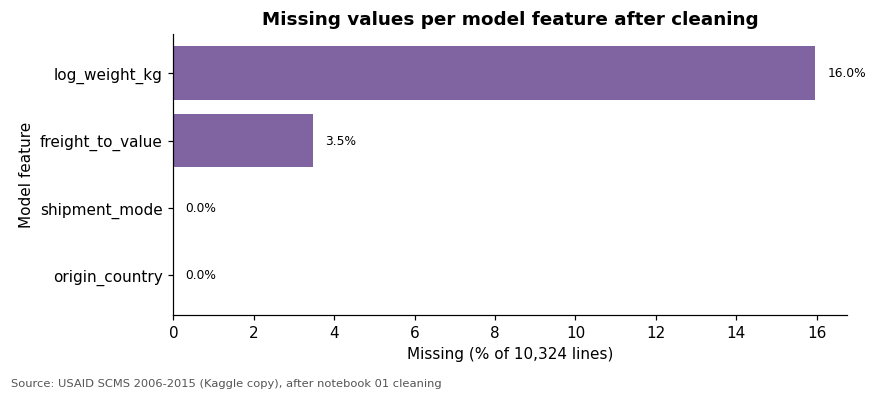

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.6))
miss_plot = missing.sort_values() * 100
ax.barh(miss_plot.index, miss_plot.values, color=PALETTE[3])
ax.set_title("Missing values per model feature after cleaning")
ax.set_xlabel("Missing (% of 10,324 lines)")
ax.set_ylabel("Model feature")
for i, v in enumerate(miss_plot.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)
save_fig(fig, "fig_03_scms_feature_missing", "USAID SCMS 2006-2015 (Kaggle copy), after notebook 01 cleaning")
plt.show()

**Business interpretation.** Only weight has a material gap (16.0% missing); the freight ratio is missing for 3.5% of lines and origin and mode for none. XGBoost handles these gaps natively, so no rows are dropped.

In [17]:
keep = ["ID", "Project Code", "Country", "Managed By", "Fulfill Via", "Vendor INCO Term", "shipment_mode", "Scheduled Delivery Date",
        "Delivered to Client Date", "sched_year", "delay_days", "late", "Product Group", "Sub Classification", "Vendor",
        "Molecule/Test Type", "Dosage Form", "Line Item Quantity", "Line Item Value", "Pack Price", "Unit Price",
        "Manufacturing Site", "origin_country", "confidence", "freight_status", "freight_usd", "weight_kg", "insurance_usd",
        "freight_to_value", "insurance_to_value", "log_weight_kg", "log_line_value", "is_air", "landed_unit_cost"]
clean = df[keep].rename(columns={"Country": "destination_country", "confidence": "origin_confidence"})
clean.to_csv(PROCESSED / "scms_clean.csv", index=False)
site.to_csv(PROCESSED / "site_features.csv")
shape("Saved data/processed/scms_clean.csv", clean)
shape("Saved data/processed/site_features.csv", site)

Saved data/processed/scms_clean.csv: 10,324 rows x 34 columns
Saved data/processed/site_features.csv: 88 rows x 8 columns


**Business interpretation.** The clean training table (10,324 lines, 34 columns) and the 88-site feature table are saved. Nothing was invented: every resolved value comes from the file itself, and every unresolved value is an explicit missing value with a status flag.

**Section summary.** The cleaned table keeps every row, has a clearly defined target, and contains only transferable features. It is saved for notebook 03 (models) and notebook 02 (the 2026 scoring panel uses the origin-level freight ratios).

## 6. Conclusion

**Section intro.** What we learned and what to do with it.

**Recommendation.** Use the cleaned SCMS table as the training layer for the delivery-risk model (C2) and the price-integrity model (C3), with these settings justified by the numbers above:
- Train on lines scheduled up to 2013 (7,779 lines, 10.7% late) and test on 2014-2015 (2,545 lines, 14.0% late).
- Use the transferable features named in override 2: origin country, shipment mode, freight-to-value ratio and log weight, plus a site prior built from the training years only. Insurance ratio and line value feed the landed-cost and anomaly engines, not the delivery model.
- Handle the 8.4 to 1 class imbalance with scale_pos_weight and judge the model on recall and ROC-AUC.
- Use the origin-level median freight and insurance ratios (for example India 5.1% and 0.14%, United States 8.7% and 0.16%) as the landed-cost markup in notebook 02.

**What this data cannot do.** It contains no carboplatin and no GCC destination, so it teaches lane behaviour, not supplier identity (assumption A2). Only Aurobindo (parent of Eugia) and Gland Pharma appear in it among the 11 carboplatin makers.

**Future improvements.**
- Replace SCMS with the GPO's own ERP delivery history and Tatmeen scan timestamps when the pilot starts.
- Test the model on the newer USAID GHSC-PSM delivery data (to 2024) as an out-of-time check.
- Have a team member re-verify the 16 inferred site countries in pipeline/reference/site_country_map.csv.

**End of notebook 01.** Next: notebook 02 builds the 2026 carboplatin scoring panel.